# Steam Reviews 2021 — Data Mining Final Project
## Notebook 03 · Part 1, section 5: Feature Engineering

| Subsection | Assignment requirement |
|---|---|
| 5.1 | Create at least two new meaningful features (11 are created, 5 more are rejected because of leakage) |
| 5.2 | Apply feature selection: filter methods (ANOVA F, mutual information, Spearman), quasi-constant and redundancy filters, **RFECV**, chi² selection of text terms, feature-group comparison |
| 5.3 | Use PCA when appropriate: PCA on numeric features, TruncatedSVD (LSA) on TF-IDF |
| 5.4 | Explain which features were retained or removed |
| 5.5 | Final feature pipeline and conclusion |

**Inputs:** `data/processed/{train,val,test}.parquet` from notebook 01.
**Rules:** everything that is *learned* (scaling, TF-IDF vocabulary, chi² scores, RFECV, PCA) is fitted on **train**. Selection decisions are compared on **validation**. The **test** set only receives the new columns and is never scored here.

The probe model for all comparisons is a class-weighted logistic regression: fast, works with sparse TF-IDF, and its coefficients are interpretable. Choosing and tuning the final classifier is part 2 of the project.

Runtime on the full sample: roughly 5–15 minutes (TF-IDF and several logistic regressions on ~140,000 texts).

## 0. Setup

In [1]:
import json
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import sparse, stats
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_selection import RFECV, chi2, f_classif, mutual_info_classif
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder

from src import config as C
from src import eda as E
from src import features as F

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 110)
sns.set_theme(style="whitegrid", context="notebook")
for folder in (C.FIGURES_DIR, C.TABLES_DIR, C.MODELS_DIR, C.DATA_PROCESSED):
    folder.mkdir(parents=True, exist_ok=True)

NEG, POS = "Not recommended", "Recommended"
PALETTE = {NEG: "#c0392b", POS: "#27ae60"}
MIN_GAIN = 0.002


def savefig(name):
    plt.tight_layout()
    plt.savefig(C.FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def to_dense(matrix):
    return matrix.toarray() if sparse.issparse(matrix) else np.asarray(matrix)


print(f"python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__}")

python 3.12.1 | pandas 3.1.1 | numpy 2.5.5


In [2]:
splits = {name: pd.read_parquet(C.DATA_PROCESSED / f"{name}.parquet") for name in ("train", "val", "test")}
splits = {name: F.add_engineered_features(part) for name, part in splits.items()}
train, val, test = splits["train"], splits["val"], splits["test"]
y_train = train[C.TARGET].to_numpy()
y_val = val[C.TARGET].to_numpy()
label_train = np.where(y_train == 1, POS, NEG)
display(pd.DataFrame({"rows": [len(train), len(val), len(test)],
                      "negative_%": [100 * (1 - p[C.TARGET].mean()) for p in (train, val, test)]},
                     index=["train", "validation", "test"]).round(2))

,rows,negative_%
train,132350,10.97
validation,28361,10.97
test,28361,10.97


## 5.1 New features

All new features are **row-level formulas**: each value is computed from the same review only, nothing is estimated from other rows. Therefore they are computed in the same way for train, validation and test without any leakage. Every feature uses only information that exists **at the moment the review is written**.

In [3]:
display(F.FEATURE_DEFINITIONS)

,definition,why it can matter
feature,,
word_count,number of words in review_clean,"effort and emotion: complaints tend to be explained, praise is often short"
char_count,number of characters in review_clean,"alternative length measure, checked for redundancy with word_count"
avg_word_length,letters / words,writing style: short slang words vs. elaborated text
exclamation_count,number of '!' in the original text,emotional intensity
question_count,number of '?' in the original text,rhetorical questions are typical for complaints
uppercase_ratio,upper-case letters / all letters in the original text,'shouting' in capitals
negation_count,"occurrences of not, no, never, nothing, n't, ...",negations flip the meaning of positive words
negation_ratio,negation_count / word_count,negation density independent of length
has_formatting,1 if the original text contains Steam BBCode tags,"formatted reviews are structured, detailed reviews"


### 5.1.1 How the new features differ between the classes

In [4]:
rows = []
for col in F.ENGINEERED:
    x = train[col]
    ok = x.notna().to_numpy()
    rho, p_value = stats.spearmanr(x[ok], y_train[ok]) if x[ok].nunique() > 1 else (np.nan, np.nan)
    rows.append({
        "feature": col,
        "mean (Not rec.)": x[y_train == 0].mean(),
        "mean (Rec.)": x[y_train == 1].mean(),
        "median (Not rec.)": x[y_train == 0].median(),
        "median (Rec.)": x[y_train == 1].median(),
        "spearman with target": rho,
        "p": E.fmt_p(p_value),
        "effect": E.effect_label(rho, "rho"),
        "missing": int(x.isna().sum()),
    })
new_feature_stats = pd.DataFrame(rows).set_index("feature")
new_feature_stats = new_feature_stats.reindex(new_feature_stats["spearman with target"].abs().sort_values(ascending=False).index)
new_feature_stats.to_csv(C.TABLES_DIR / "fe_new_feature_stats.csv")
display(new_feature_stats.round(4))

useful = new_feature_stats[~new_feature_stats["effect"].isin(["negligible", "n/a"])].index.tolist()
constant = new_feature_stats[new_feature_stats["effect"] == "n/a"].index.tolist()
if constant:
    print(f"Constant in the training set (no information): {constant}")
print(f"New features with at least a small monotonic relation to the target (|rho| >= 0.1): {useful or 'none'}")

,mean (Not rec.),mean (Rec.),median (Not rec.),median (Rec.),spearman with target,p,effect,missing
feature,,,,,,,,
negation_count,1.7354,0.5045,1.0000,0.0000,-0.2508,< 1e-300,small,0
negation_ratio,0.0327,0.0100,0.0137,0.0000,-0.2456,< 1e-300,small,0
char_count,410.6664,191.3875,157.0000,55.0000,-0.1795,< 1e-300,small,0
word_count,75.6306,35.3241,29.0000,10.0000,-0.1759,< 1e-300,small,0
question_count,0.2609,0.0784,0.0000,0.0000,-0.1103,< 1e-300,small,0
review_age_days,978.4471,809.3727,972.0778,532.1299,-0.1053,< 1e-300,small,0
avg_word_length,4.3715,4.5527,4.1743,4.0000,-0.0565,5.89e-94,negligible,0
exclamation_count,0.3503,0.3893,0.0000,0.0000,0.0328,6.94e-33,negligible,0
reviews_per_game_owned,0.1141,0.1292,0.0625,0.0714,0.0316,1.30e-30,negligible,0


New features with at least a small monotonic relation to the target (|rho| >= 0.1): ['negation_count', 'negation_ratio', 'char_count', 'word_count', 'question_count', 'review_age_days']


A negative Spearman ρ means the feature is larger in *Not recommended* reviews (target = 0). Single features are expected to be weak or moderate predictors; their value is in combination with the text, which is tested in 5.2.7.

### Figure 18 — new features by class

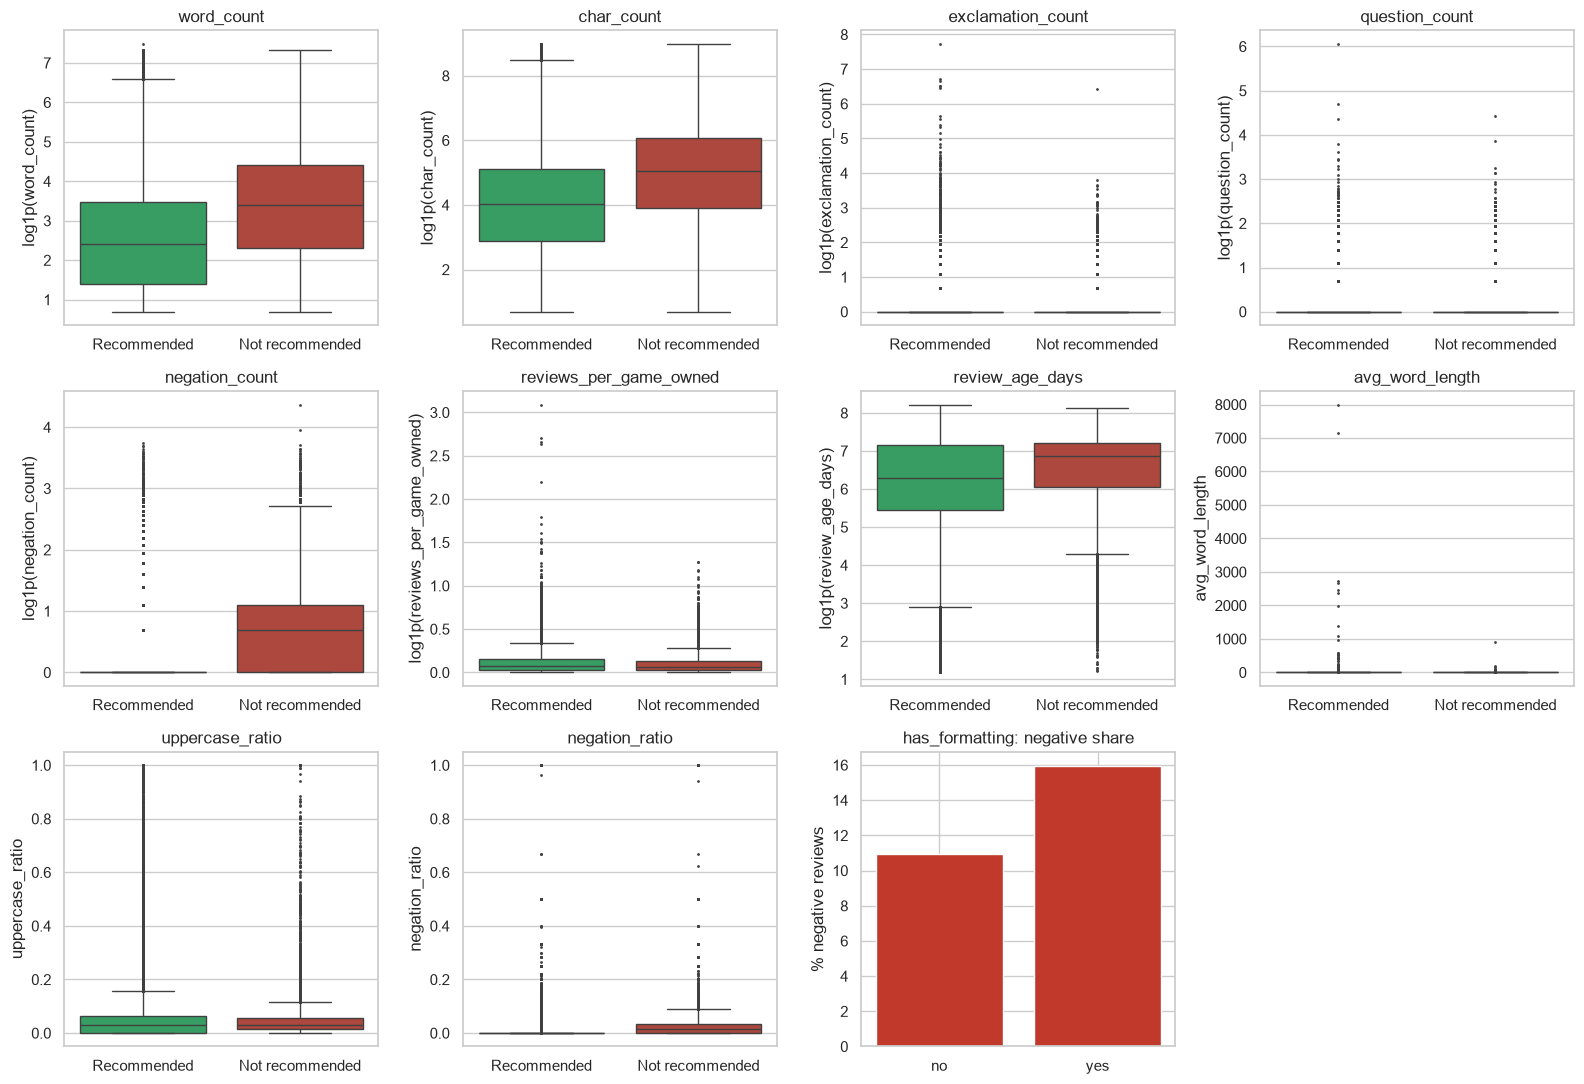

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, col in zip(axes.ravel(), F.ENGINEERED):
    if col in F.ENGINEERED_BINARY:
        rate = pd.Series(1 - y_train).groupby(train[col].to_numpy()).mean() * 100
        ax.bar(["yes" if v == 1 else "no" for v in rate.index], rate.values, color="#c0392b")
        ax.set_ylabel("% negative reviews")
        ax.set_title(f"{col}: negative share")
        continue
    values = np.log1p(train[col]) if col in F.ENGINEERED_LOG else train[col]
    tmp = pd.DataFrame({"value": values.to_numpy(), "label": label_train}).dropna()
    sns.boxplot(data=tmp, x="label", y="value", hue="label", order=[POS, NEG], hue_order=[POS, NEG],
                palette=PALETTE, legend=False, fliersize=1, ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel(f"log1p({col})" if col in F.ENGINEERED_LOG else col)
    ax.set_title(col)
for ax in axes.ravel()[len(F.ENGINEERED):]:
    ax.axis("off")
savefig("18_new_features_by_class")

Count features are shown on the `log1p` scale for readability (the same transformation is used in the pipeline). A shift of the box between the two classes indicates that the feature carries information about the label.

### 5.1.2 Rejected candidate features (leakage)
These candidates look attractive and may even correlate strongly with the target, but they use information that appears **after** the review is published. A model that relies on them would perform well in the notebook and fail on a freshly written review, so they are not used.

In [6]:
leak = F.add_leakage_candidates(train)
leak_rows = []
for col in F.LEAKAGE_CANDIDATES.index:
    x = leak[col]
    ok = x.notna().to_numpy()
    rho = stats.spearmanr(x[ok], y_train[ok])[0] if x[ok].nunique() > 1 else np.nan
    leak_rows.append({"candidate": col, "spearman with target": rho})
leakage_table = F.LEAKAGE_CANDIDATES.join(pd.DataFrame(leak_rows).set_index("candidate"))
leakage_table["decision"] = "removed: leakage"
display(leakage_table.round(3))

,definition,why it is rejected,spearman with target,decision
candidate,,,,
playtime_ratio,author_playtime_at_review / author_playtime_forever,author_playtime_forever is measured after the review,-0.127,removed: leakage
was_edited,1 if updated_at > created_at,an edit happens after publication,-0.116,removed: leakage
log_votes_helpful,log1p(votes_helpful),votes are given by other users after publication,-0.283,removed: leakage
log_comment_count,log1p(comment_count),comments appear after publication,-0.167,removed: leakage
days_since_last_played,end of collection - last_played_at,describes behaviour after the review,-0.162,removed: leakage


## 5.2 Feature selection

Two kinds of features are selected separately because they have very different sizes:
* **tabular features** (14 numeric/boolean candidates + missing-value flags) → filter methods → quasi-constant filter → redundancy filter → **RFECV**;
* **text features** (up to 100,000 TF-IDF terms) → **chi²** ranking, number of terms chosen on validation.

Finally whole groups (text / tabular / game) are compared on validation to decide which groups enter the final pipeline.

### 5.2.1 Tabular candidate matrix
Same transformations as in notebook 01: clip to the train 0.1 %/99.9 % quantiles → `log1p` for counts → median imputation → standardisation; boolean features are imputed with the most frequent value; one 0/1 flag per author feature marks imputed values.

In [7]:
tab_pipe = F.build_feature_pipeline(
    include_text=False,
    include_games=False,
    log_features=F.LOG_FEATURES,
    linear_features=F.LINEAR_FEATURES,
    binary_features=F.BINARY_FEATURES,
    missing_features=F.MISSING_FEATURES,
)


def tidy(name):
    group, raw = name.split("__", 1)
    if group == "missing":
        raw = "missing_" + raw.replace("missingindicator_", "")
    return group, raw


tab_names = [tidy(n) for n in tab_pipe.fit(train).get_feature_names_out()]
feature_group = {raw: group for group, raw in tab_names}
tab_columns = [raw for _, raw in tab_names]
X_tab_train = pd.DataFrame(to_dense(tab_pipe.transform(train)).astype("float64"), columns=tab_columns, index=train.index)
X_tab_val = pd.DataFrame(to_dense(tab_pipe.transform(val)).astype("float64"), columns=tab_columns, index=val.index)
print(f"Tabular candidates: {len(tab_columns)}")
display(pd.Series(feature_group).value_counts().rename("features per group").to_frame())

Tabular candidates: 20


,features per group
log,10
binary,4
linear,3
missing,3


### 5.2.2 Filter methods
* **ANOVA F-test** (`f_classif`): does the mean of the feature differ between the classes? Linear, fast.
* **Mutual information**: how much knowing the feature reduces uncertainty about the label; captures non-linear relations (estimated on up to 50,000 training rows).
* **Spearman ρ** with the target: strength and direction of a monotonic relation.

,group,top value share,mutual_info,anova_F,anova_p,spearman
review_age_days,log,0.0010,0.0353,1438.6019,< 1e-300,-0.1053
negation_count,log,0.7379,0.0328,9320.8972,< 1e-300,-0.2508
negation_ratio,linear,0.7379,0.0290,4163.1065,< 1e-300,-0.2456
char_count,log,0.0281,0.0175,4593.8775,< 1e-300,-0.1795
word_count,log,0.0938,0.0166,4623.9866,< 1e-300,-0.1759
avg_word_length,linear,0.0955,0.0153,17.7081,2.58e-05,-0.0565
author_playtime_at_review,log,0.0016,0.0147,855.6128,1.74e-187,0.0579
uppercase_ratio,linear,0.2648,0.0126,21.5473,3.46e-06,-0.0151
question_count,log,0.9499,0.0047,1768.9969,< 1e-300,-0.1103
reviews_per_game_owned,log,0.0146,0.0044,129.5697,5.26e-30,0.0316


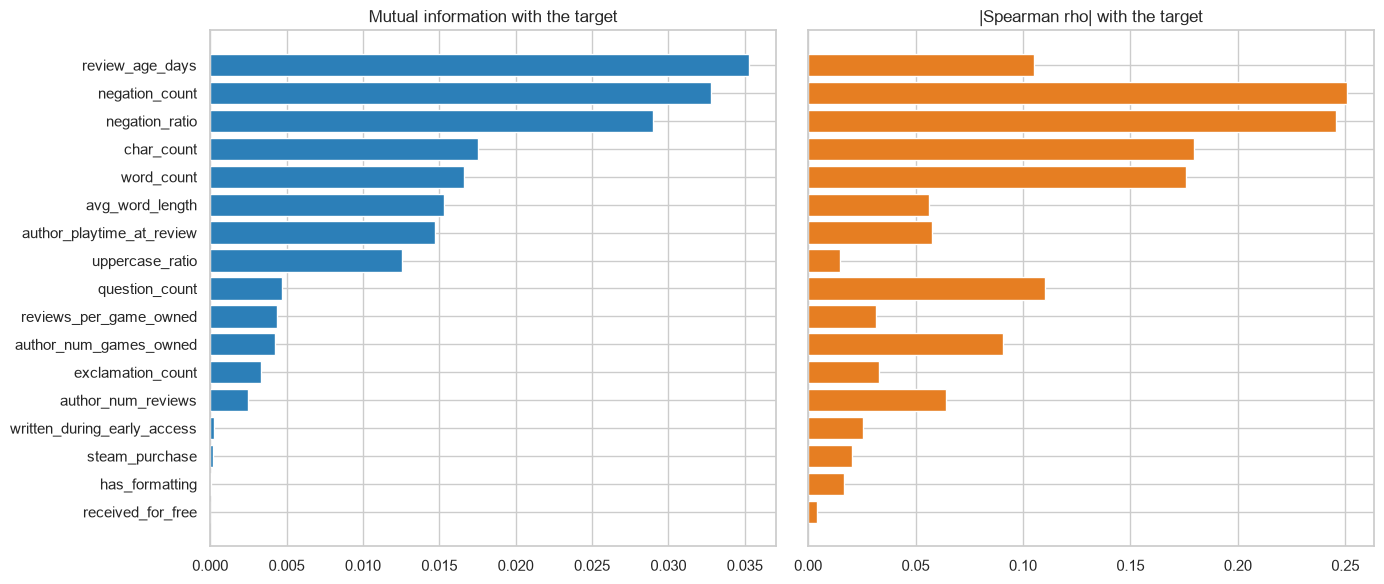

In [8]:
non_constant = X_tab_train.columns[X_tab_train.nunique() > 1].tolist()
rng = np.random.default_rng(C.RANDOM_STATE)
sub = rng.choice(len(X_tab_train), size=min(50_000, len(X_tab_train)), replace=False)
discrete = np.array([feature_group[c] in ("binary", "missing") for c in non_constant])
mi = mutual_info_classif(X_tab_train[non_constant].to_numpy()[sub], y_train[sub],
                         discrete_features=discrete, random_state=C.RANDOM_STATE)
f_stat, f_p = f_classif(X_tab_train[non_constant], y_train)
rho = [stats.spearmanr(X_tab_train[c], y_train)[0] for c in non_constant]

filter_table = pd.DataFrame({
    "group": [feature_group[c] for c in tab_columns],
    "top value share": [X_tab_train[c].value_counts(normalize=True).iloc[0] for c in tab_columns],
}, index=tab_columns)
filter_table.loc[non_constant, "mutual_info"] = mi
filter_table.loc[non_constant, "anova_F"] = f_stat
filter_table.loc[non_constant, "anova_p"] = f_p
filter_table.loc[non_constant, "spearman"] = rho
filter_table = filter_table.sort_values("mutual_info", ascending=False)
display(filter_table.assign(anova_p=filter_table["anova_p"].map(E.fmt_p)).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
order = filter_table.dropna(subset=["mutual_info"]).index
axes[0].barh(order[::-1], filter_table.loc[order[::-1], "mutual_info"], color="#2c7fb8")
axes[0].set_title("Mutual information with the target")
axes[1].barh(order[::-1], filter_table.loc[order[::-1], "spearman"].abs(), color="#e67e22")
axes[1].set_title("|Spearman rho| with the target")
savefig("19_filter_scores_tabular")

Filter methods rank every feature **on its own**. They are used here to understand the features and to break ties in the redundancy filter; the final choice is made by RFECV, which evaluates features **together** in a model.

### 5.2.3 Quasi-constant features
A feature whose most frequent value covers more than 99.5 % of the training rows carries almost no information and makes coefficients unstable.

In [9]:
quasi_constant = filter_table.index[filter_table["top value share"] > 0.995].tolist()
print(f"Quasi-constant features removed: {quasi_constant or 'none'}")
display(filter_table.loc[quasi_constant, ["group", "top value share"]] if quasi_constant else None)

Quasi-constant features removed: ['missing_author_num_games_owned', 'missing_author_num_reviews', 'missing_author_playtime_at_review']


,group,top value share
missing_author_num_games_owned,missing,1.0
missing_author_num_reviews,missing,1.0
missing_author_playtime_at_review,missing,1.0


### 5.2.4 Redundancy filter
If two features have |Spearman ρ| > 0.9 they describe almost the same thing. Keeping both doubles the information in a linear model (multicollinearity, unstable coefficients). From each such pair the feature with **lower mutual information** is removed.

,feature_a,feature_b,rho
0,word_count,char_count,0.988
1,negation_count,negation_ratio,0.970


Removed as redundant: word_count (kept char_count, rho = 0.99), negation_ratio (kept negation_count, rho = 0.97)


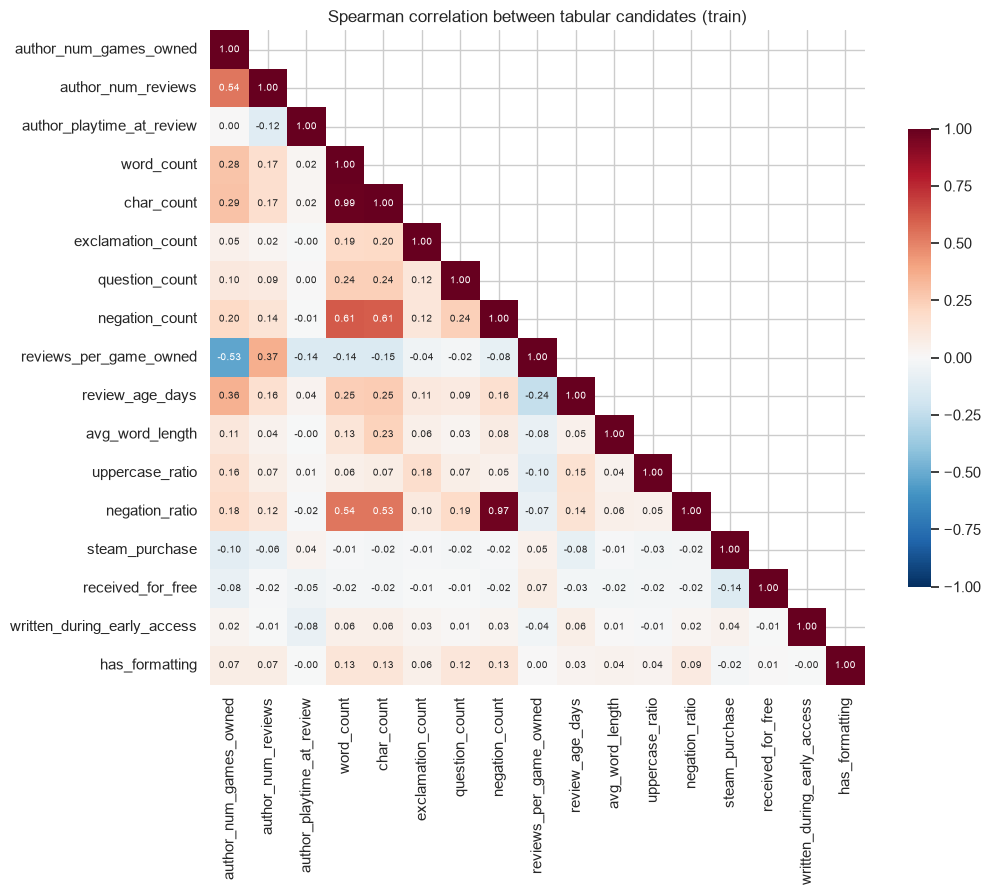

In [10]:
candidates = [c for c in tab_columns if c not in quasi_constant]
corr_candidates = X_tab_train[candidates].corr(method="spearman")
pairs = E.strong_pairs(corr_candidates, 0.9)
redundant = {}
for _, row in pairs.iterrows():
    a, b = row["feature_a"], row["feature_b"]
    if a in redundant or b in redundant:
        continue
    mi_a = filter_table.loc[a, "mutual_info"]
    mi_b = filter_table.loc[b, "mutual_info"]
    drop, keep = (a, b) if mi_a < mi_b else (b, a)
    redundant[drop] = (keep, row["rho"])
display(pairs.round(3) if len(pairs) else "No pair with |rho| > 0.9")
print(f"Removed as redundant: {', '.join(f'{d} (kept {k}, rho = {r:.2f})' for d, (k, r) in redundant.items()) or 'none'}")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_candidates, mask=np.triu(np.ones_like(corr_candidates, dtype=bool), k=1), cmap="RdBu_r",
            vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Spearman correlation between tabular candidates (train)")
savefig("20_tabular_feature_correlation")

### 5.2.5 Recursive Feature Elimination with Cross-Validation (RFECV)
RFECV is a **wrapper** method: it fits the logistic regression, removes the feature with the smallest absolute coefficient, refits, and repeats until one feature is left. For every number of features the model is evaluated with **5-fold stratified cross-validation on the training set**; the number with the best mean score is selected.

Scoring is ROC-AUC: it does not depend on a classification threshold and treats both classes symmetrically, so the ranking of features is not distorted by the class imbalance. Features are standardised, therefore coefficient sizes are comparable.

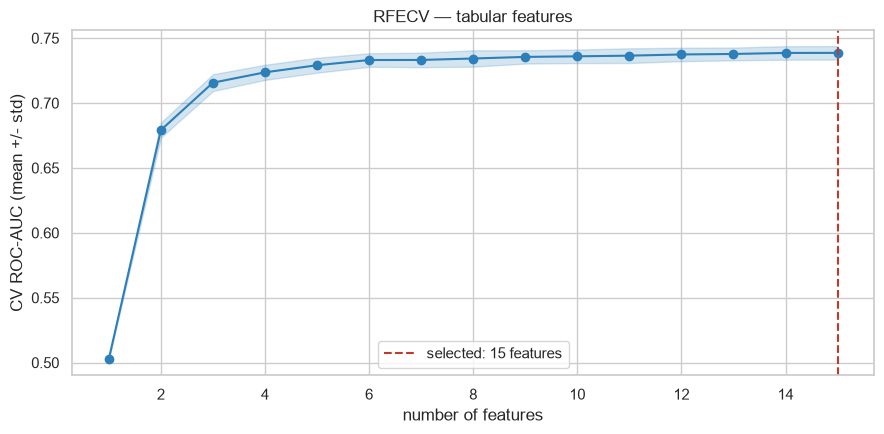

,rfe_rank,selected,coefficient
has_formatting,1,True,0.9074
negation_count,1,True,-0.5405
review_age_days,1,True,-0.2843
exclamation_count,1,True,0.2469
author_playtime_at_review,1,True,0.2069
char_count,1,True,-0.1702
written_during_early_access,1,True,-0.1159
author_num_reviews,1,True,-0.1102
question_count,1,True,-0.1019
steam_purchase,1,True,0.0900


Best CV ROC-AUC 0.7387 with 15 of 15 features
Selected: ['author_num_games_owned', 'author_num_reviews', 'author_playtime_at_review', 'char_count', 'exclamation_count', 'question_count', 'negation_count', 'reviews_per_game_owned', 'review_age_days', 'avg_word_length', 'uppercase_ratio', 'steam_purchase', 'received_for_free', 'written_during_early_access', 'has_formatting']


In [11]:
rfe_features = [c for c in candidates if c not in redundant]
rfecv = RFECV(
    estimator=F.probe_model(sparse=False),
    step=1,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=C.RANDOM_STATE),
    scoring="roc_auc",
    min_features_to_select=1,
    n_jobs=-1,
)
rfecv.fit(X_tab_train[rfe_features], y_train)
cv_mean = rfecv.cv_results_["mean_test_score"]
cv_std = rfecv.cv_results_["std_test_score"]
n_grid = np.arange(1, len(cv_mean) + 1)
selected_tab = [c for c, keep in zip(rfe_features, rfecv.support_) if keep]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(n_grid, cv_mean, marker="o", color="#2c7fb8")
ax.fill_between(n_grid, cv_mean - cv_std, cv_mean + cv_std, alpha=0.2, color="#2c7fb8")
ax.axvline(rfecv.n_features_, ls="--", color="#c0392b", label=f"selected: {rfecv.n_features_} features")
ax.set_xlabel("number of features")
ax.set_ylabel("CV ROC-AUC (mean +/- std)")
ax.set_title("RFECV — tabular features")
ax.legend()
savefig("21_rfecv_tabular")

coef = pd.Series(rfecv.estimator_.coef_.ravel(), index=selected_tab)
rfe_table = pd.DataFrame({"rfe_rank": rfecv.ranking_, "selected": rfecv.support_}, index=rfe_features)
rfe_table["coefficient"] = coef
rfe_table["abs_coefficient"] = coef.abs()
rfe_table = rfe_table.sort_values(["rfe_rank", "abs_coefficient"], ascending=[True, False]).drop(columns="abs_coefficient")
rfe_table.to_csv(C.TABLES_DIR / "fe_rfecv_ranking.csv")
display(rfe_table.round(4))
print(f"Best CV ROC-AUC {cv_mean.max():.4f} with {rfecv.n_features_} of {len(rfe_features)} features")
print(f"Selected: {selected_tab}")

Rank 1 means *selected*; higher ranks were eliminated earlier (rank 2 was the last one removed). A positive coefficient pushes the prediction towards *Recommended*, a negative one towards *Not recommended*. If the curve is flat around the optimum, fewer features give almost the same score, which is why RFECV removes features that add nothing.

### 5.2.6 Text features: TF-IDF and chi² selection
TF-IDF (term frequency × inverse document frequency) gives a high weight to words that are frequent in a review but rare in the collection. Settings: unigrams and bigrams (to capture *not worth*, *waste of*), terms in at least 5 reviews and at most 90 % of reviews, sublinear term frequency, at most 100,000 terms. Stop words are **not** removed, because standard stop-word lists contain negations (*not*, *no*), which are important for sentiment.

The **chi² test** measures how strongly each term depends on the class. Terms are ranked by chi² on train, and the number of kept terms *k* is chosen by the validation F1-macro of the probe model.

TF-IDF matrix: train (132350, 100000), validation (28361, 100000); non-zero share 0.00050


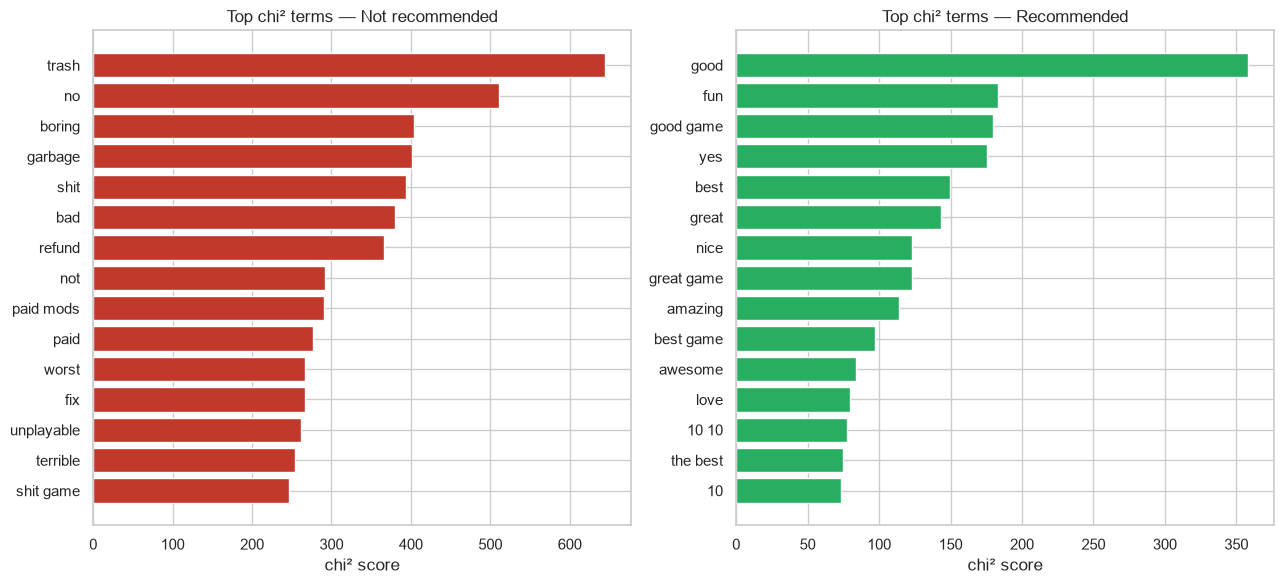

In [12]:
text_pipe = F.build_text_pipeline()
X_text_train = text_pipe.fit_transform(train[C.TEXT_CLEAN])
X_text_val = text_pipe.transform(val[C.TEXT_CLEAN])
vocab = text_pipe.named_steps["tfidf"].get_feature_names_out()
n_vocab = len(vocab)
print(f"TF-IDF matrix: train {X_text_train.shape}, validation {X_text_val.shape}; "
      f"non-zero share {X_text_train.nnz / np.prod(X_text_train.shape):.5f}")

chi_scores, chi_p = chi2(X_text_train, y_train)
chi_scores = np.nan_to_num(chi_scores)
neg_mean = np.asarray(X_text_train[y_train == 0].mean(axis=0)).ravel()
pos_mean = np.asarray(X_text_train[y_train == 1].mean(axis=0)).ravel()
chi_table = pd.DataFrame({"term": vocab, "chi2": chi_scores, "p": chi_p,
                          "more typical for": np.where(neg_mean > pos_mean, NEG, POS)})
chi_table = chi_table.sort_values("chi2", ascending=False).reset_index(drop=True)
chi_table.head(500).to_csv(C.TABLES_DIR / "fe_text_chi2_top500.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, cls in zip(axes, [NEG, POS]):
    top = chi_table[chi_table["more typical for"] == cls].head(15)
    ax.barh(top["term"][::-1], top["chi2"][::-1], color=PALETTE[cls])
    ax.set_title(f"Top chi² terms — {cls}")
    ax.set_xlabel("chi² score")
savefig("22_text_chi2_terms")

,terms,f1_macro,recall_negative,pr_auc_negative,roc_auc
k,,,,,
1000,1000,0.7561,0.8310,0.6925,0.9276
5000,5000,0.7816,0.8499,0.7356,0.9430
20000,20000,0.8024,0.8560,0.7590,0.9510
50000,50000,0.8123,0.8602,0.7755,0.9544
all,100000,0.8172,0.8554,0.7808,0.9555


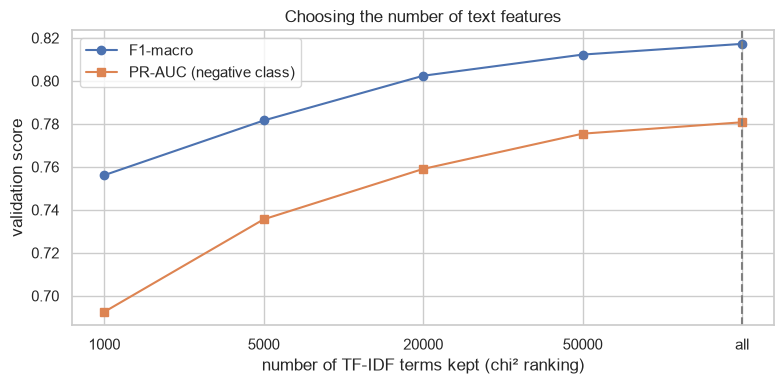

Selected k = all terms (100,000 of 100,000) — best validation F1-macro 0.8172


In [13]:
term_order = np.argsort(chi_scores)[::-1]
k_grid = [k for k in (1_000, 5_000, 20_000, 50_000) if k < n_vocab] + ["all"]
k_rows = []
for k in k_grid:
    idx = term_order if k == "all" else term_order[:k]
    model = F.probe_model().fit(X_text_train[:, idx], y_train)
    k_rows.append({"k": str(k), "terms": len(idx), **F.validation_scores(model, X_text_val[:, idx], y_val)})
k_table = pd.DataFrame(k_rows).set_index("k")
k_table.to_csv(C.TABLES_DIR / "fe_text_k_selection.csv")
display(k_table.round(4))

best_k_label = k_table["f1_macro"].idxmax()
k_star = "all" if best_k_label == "all" else int(best_k_label)
text_idx = term_order if k_star == "all" else term_order[:k_star]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_table.index, k_table["f1_macro"], marker="o", label="F1-macro")
ax.plot(k_table.index, k_table["pr_auc_negative"], marker="s", label="PR-AUC (negative class)")
ax.axvline(list(k_table.index).index(best_k_label), ls="--", color="grey")
ax.set_xlabel("number of TF-IDF terms kept (chi² ranking)")
ax.set_ylabel("validation score")
ax.set_title("Choosing the number of text features")
ax.legend()
savefig("23_text_k_selection")
print(f"Selected k = {k_star} terms ({len(text_idx):,} of {n_vocab:,}) — best validation F1-macro "
      f"{k_table.loc[best_k_label, 'f1_macro']:.4f}")

If a small *k* reaches almost the same score as all terms, most terms are noise for the classifier; if the score keeps growing with *k*, many rare terms carry useful sentiment. In case of a tie, the smaller *k* is preferred (simpler model, less overfitting).

### 5.2.7 Feature-group comparison on validation
Each group is added only if it helps the probe model on validation data. Text features use the selected *k*, tabular features the RFECV selection, games are one-hot encoded (games with fewer than 20 training reviews are pooled).

,features,f1_macro,recall_negative,pr_auc_negative,roc_auc
groups,,,,,
text,100000,0.8172,0.8554,0.7808,0.9555
text + game,100282,0.8223,0.8715,0.7972,0.9602
text + tabular,100015,0.8166,0.8554,0.7869,0.9567
text + tabular + game,100297,0.8254,0.8766,0.8055,0.9620
tabular + game,297,0.6384,0.7600,0.4420,0.8443


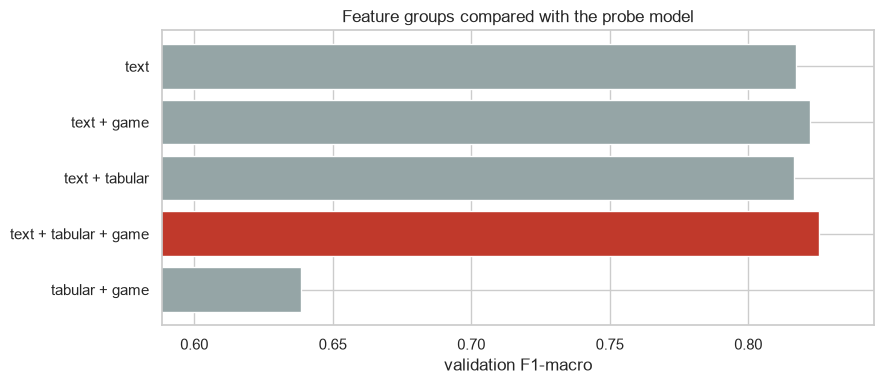

Best combination: text + tabular + game (F1-macro 0.8254)


In [14]:
game_encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=True)
X_game_train = game_encoder.fit_transform(train[C.CAT_FEATURES])
X_game_val = game_encoder.transform(val[C.CAT_FEATURES])
blocks_train = {"text": X_text_train[:, text_idx], "tabular": sparse.csr_matrix(X_tab_train[selected_tab].to_numpy()),
                "game": X_game_train}
blocks_val = {"text": X_text_val[:, text_idx], "tabular": sparse.csr_matrix(X_tab_val[selected_tab].to_numpy()),
              "game": X_game_val}

configs = [("text",), ("text", "game"), ("text", "tabular"), ("text", "tabular", "game"), ("tabular", "game")]
if not selected_tab:
    configs = [c for c in configs if "tabular" not in c]
group_rows = []
for groups in configs:
    Xtr = sparse.hstack([blocks_train[g] for g in groups]).tocsr()
    Xva = sparse.hstack([blocks_val[g] for g in groups]).tocsr()
    model = F.probe_model().fit(Xtr, y_train)
    group_rows.append({"groups": " + ".join(groups), "features": Xtr.shape[1],
                       **F.validation_scores(model, Xva, y_val)})
group_table = pd.DataFrame(group_rows).set_index("groups")
group_table.to_csv(C.TABLES_DIR / "fe_group_comparison.csv")
display(group_table.round(4))

best_groups = group_table["f1_macro"].idxmax()
use_text = "text" in best_groups
use_tab = "tabular" in best_groups
use_games = "game" in best_groups

fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#c0392b" if g == best_groups else "#95a5a6" for g in group_table.index]
ax.barh(group_table.index[::-1], group_table["f1_macro"][::-1], color=colors[::-1])
lo = group_table["f1_macro"].min()
ax.set_xlim(max(0, lo - 0.05), min(1, group_table["f1_macro"].max() + 0.02))
ax.set_xlabel("validation F1-macro")
ax.set_title("Feature groups compared with the probe model")
savefig("24_feature_group_comparison")
print(f"Best combination: {best_groups} (F1-macro {group_table.loc[best_groups, 'f1_macro']:.4f})")

The comparison shows how much each group adds **on top of the text**. The row without text shows how far reviewer and game information alone can go; the gap to the text rows is the contribution of the review text (RQ1). The combination with the best validation F1-macro is used in the final pipeline; ties are resolved in favour of the simpler combination (listed first).

## 5.3 PCA

### 5.3.1 PCA on the selected continuous tabular features
PCA finds uncorrelated directions (principal components) of maximal variance. It is applied only to the selected **continuous** features, which are standardised (PCA depends on scale); binary features and flags are not suitable for PCA and stay as they are.

**Criterion for "appropriate":** PCA is used in the final pipeline only if it **improves** validation F1-macro by at least 0.002. With only a handful of features there is no computational need for dimensionality reduction, and components are harder to interpret than the original features.

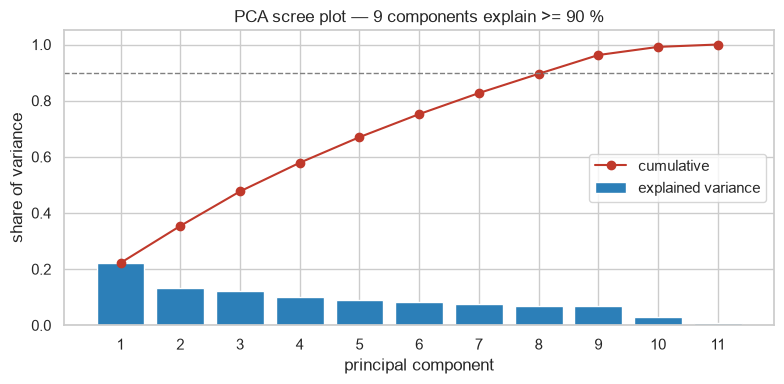

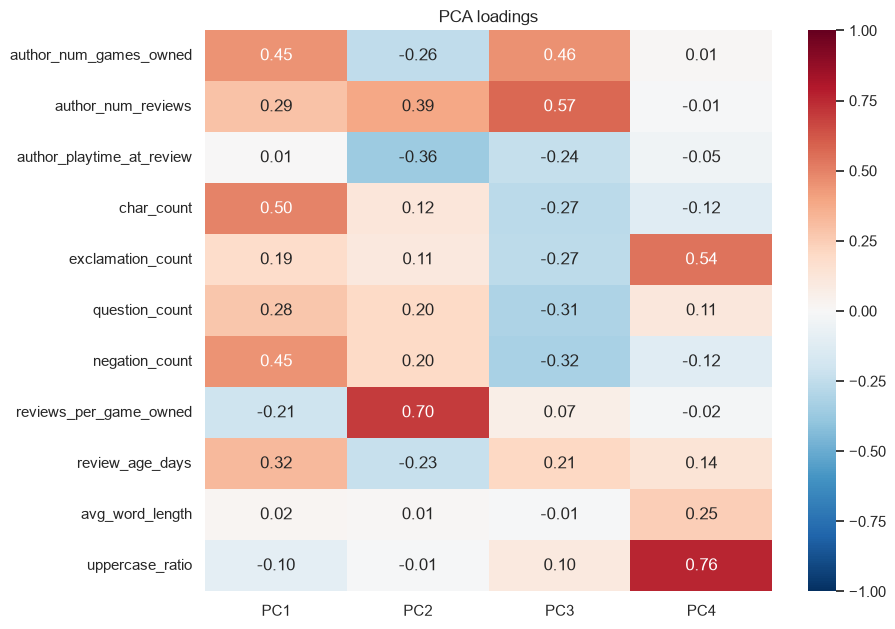

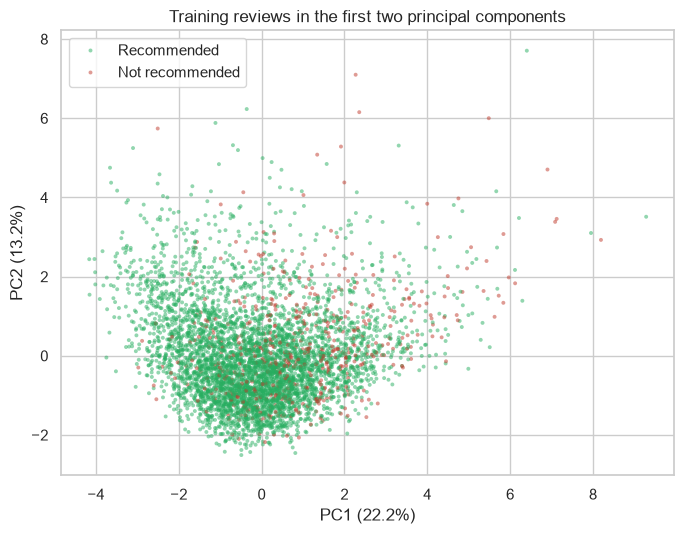

,f1_macro,recall_negative,pr_auc_negative,roc_auc
selected tabular features (15),0.5792,0.6134,0.267,0.7309
PCA 9 components + 4 binary,0.5665,0.6192,0.262,0.7273


Variance explained by 9 of 11 components: 96.3%
Decision: PCA on tabular features is NOT used in the final pipeline.


In [15]:
pca_cols = [c for c in selected_tab if feature_group[c] in ("log", "linear")]
other_cols = [c for c in selected_tab if c not in pca_cols]
use_pca = False
n_pca = None
if len(pca_cols) >= 2:
    pca = PCA(random_state=C.RANDOM_STATE).fit(X_tab_train[pca_cols])
    evr = pca.explained_variance_ratio_
    cum = np.cumsum(evr)
    n_pca = int(np.searchsorted(cum, 0.90) + 1)

    fig, ax = plt.subplots(figsize=(8, 4))
    pcs = np.arange(1, len(evr) + 1)
    ax.bar(pcs, evr, color="#2c7fb8", label="explained variance")
    ax.plot(pcs, cum, marker="o", color="#c0392b", label="cumulative")
    ax.axhline(0.9, ls="--", color="grey", lw=1)
    ax.set_xticks(pcs)
    ax.set_xlabel("principal component")
    ax.set_ylabel("share of variance")
    ax.set_title(f"PCA scree plot — {n_pca} components explain >= 90 %")
    ax.legend()
    savefig("25_pca_scree")

    n_show = min(4, len(evr))
    loadings = pd.DataFrame(pca.components_[:n_show].T, index=pca_cols, columns=[f"PC{i}" for i in range(1, n_show + 1)])
    fig, ax = plt.subplots(figsize=(1.6 * n_show + 3, 0.45 * len(pca_cols) + 1.5))
    sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
    ax.set_title("PCA loadings")
    savefig("26_pca_loadings")

    scores_2d = pca.transform(X_tab_train[pca_cols])[:, :2]
    show = rng.choice(len(scores_2d), size=min(5000, len(scores_2d)), replace=False)
    fig, ax = plt.subplots(figsize=(7, 5.5))
    sns.scatterplot(x=scores_2d[show, 0], y=scores_2d[show, 1], hue=label_train[show], hue_order=[POS, NEG],
                    palette=PALETTE, s=8, alpha=0.5, linewidth=0, ax=ax)
    ax.set_xlabel(f"PC1 ({evr[0]:.1%})")
    ax.set_ylabel(f"PC2 ({evr[1]:.1%})")
    ax.set_title("Training reviews in the first two principal components")
    savefig("27_pca_scatter")

    pca_n = PCA(n_components=n_pca, random_state=C.RANDOM_STATE).fit(X_tab_train[pca_cols])
    Z_train = np.hstack([pca_n.transform(X_tab_train[pca_cols]), X_tab_train[other_cols].to_numpy()])
    Z_val = np.hstack([pca_n.transform(X_tab_val[pca_cols]), X_tab_val[other_cols].to_numpy()])
    raw_scores = F.validation_scores(F.probe_model(sparse=False).fit(X_tab_train[selected_tab], y_train),
                                     X_tab_val[selected_tab], y_val)
    pca_scores = F.validation_scores(F.probe_model(sparse=False).fit(Z_train, y_train), Z_val, y_val)
    pca_table = pd.DataFrame([raw_scores, pca_scores],
                             index=[f"selected tabular features ({len(selected_tab)})",
                                    f"PCA {n_pca} components + {len(other_cols)} binary"])
    display(pca_table.round(4))
    use_pca = bool(pca_scores["f1_macro"] >= raw_scores["f1_macro"] + MIN_GAIN and n_pca < len(pca_cols))
    print(f"Variance explained by {n_pca} of {len(pca_cols)} components: {cum[n_pca - 1]:.1%}")
    if n_pca == len(pca_cols):
        print("All components are needed for 90 % of the variance: the features are weakly correlated, "
              "so PCA cannot reduce the dimensionality here.")
else:
    print("PCA is not appropriate: fewer than two continuous tabular features were selected.")
print(f"Decision: PCA on tabular features is {'USED' if use_pca else 'NOT used'} in the final pipeline.")

**Reading the plots.** The scree plot shows how quickly the variance is captured; the loadings show which original features form each component (large absolute values). If the two classes overlap strongly in the PC1–PC2 scatter, the directions of largest variance are not the directions that separate the classes — PCA is unsupervised and ignores the label, which is a common reason why it does not improve a classifier.

### 5.3.2 TruncatedSVD (Latent Semantic Analysis) on TF-IDF
Classical PCA needs centred data, which would turn the sparse TF-IDF matrix into a dense matrix of size *reviews × terms* that does not fit in memory. **TruncatedSVD** performs the same decomposition without centring and works directly on sparse data; on TF-IDF it is known as Latent Semantic Analysis (LSA). It is compared with the chi²-selected TF-IDF terms using the same probe model.

,f1_macro,recall_negative,pr_auc_negative,roc_auc
TF-IDF chi² top all terms,0.8172,0.8554,0.7808,0.9555
TruncatedSVD 100 components,0.6493,0.8281,0.4507,0.8739


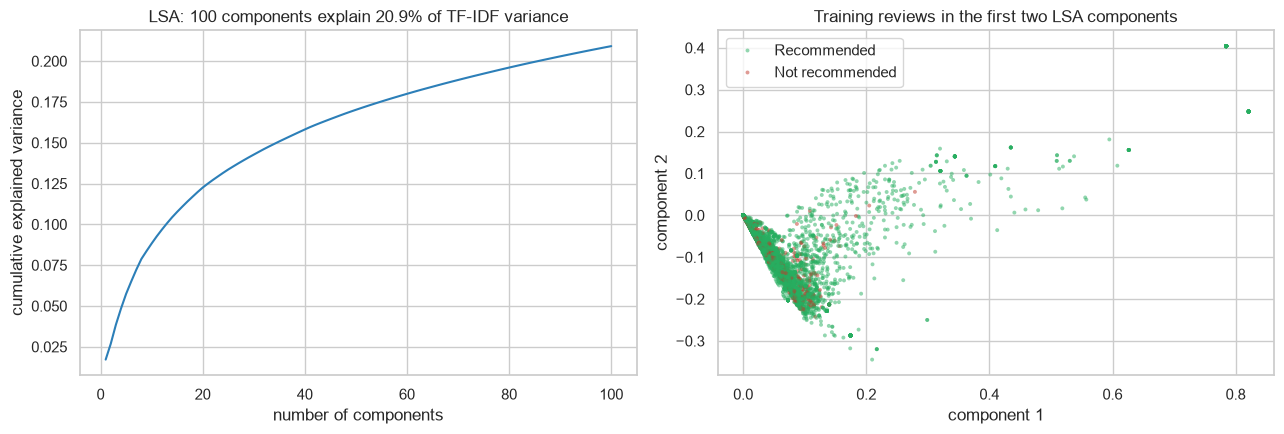

Decision: TruncatedSVD on text is NOT used in the final pipeline.


In [16]:
n_svd = int(min(100, X_text_train.shape[1] - 1, X_text_train.shape[0] - 1))
svd = TruncatedSVD(n_components=n_svd, random_state=C.RANDOM_STATE).fit(X_text_train)
svd_cum = np.cumsum(svd.explained_variance_ratio_)
S_train = svd.transform(X_text_train)
S_val = svd.transform(X_text_val)
svd_scores = F.validation_scores(F.probe_model(sparse=False).fit(S_train, y_train), S_val, y_val)
text_scores = k_table.loc[best_k_label, ["f1_macro", "recall_negative", "pr_auc_negative", "roc_auc"]].to_dict()
svd_table = pd.DataFrame([text_scores, svd_scores],
                         index=[f"TF-IDF chi² top {k_star} terms", f"TruncatedSVD {n_svd} components"])
display(svd_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(np.arange(1, n_svd + 1), svd_cum, color="#2c7fb8")
axes[0].set_xlabel("number of components")
axes[0].set_ylabel("cumulative explained variance")
axes[0].set_title(f"LSA: {n_svd} components explain {svd_cum[-1]:.1%} of TF-IDF variance")
show = rng.choice(len(S_train), size=min(5000, len(S_train)), replace=False)
sns.scatterplot(x=S_train[show, 0], y=S_train[show, 1], hue=label_train[show], hue_order=[POS, NEG],
                palette=PALETTE, s=8, alpha=0.5, linewidth=0, ax=axes[1])
axes[1].set_xlabel("component 1")
axes[1].set_ylabel("component 2")
axes[1].set_title("Training reviews in the first two LSA components")
savefig("28_text_svd")

use_svd = svd_scores["f1_macro"] >= text_scores["f1_macro"] + MIN_GAIN
print(f"Decision: TruncatedSVD on text is {'USED' if use_svd else 'NOT used'} in the final pipeline.")

TF-IDF vocabularies are very high-dimensional and each review uses only a few terms, so the variance is spread over thousands of directions and 100 components keep only a part of it. Sentiment often lives in specific words (*refund*, *masterpiece*) that a low-rank approximation blurs together with neutral topic words. The decision above is taken from the validation scores, not from this expectation.

## 5.4 Retained and removed features

In [17]:
use_pca = bool(use_pca and use_tab)
use_svd = bool(use_svd and use_text)
final_tab = selected_tab if use_tab else []
decision_rows = []
for col in tab_columns:
    if col in quasi_constant:
        status, reason = "removed", f"quasi-constant (top value share {filter_table.loc[col, 'top value share']:.2%})"
    elif col in redundant:
        keep, r = redundant[col]
        status, reason = "removed", f"redundant with {keep} (rho = {r:.2f}), lower mutual information"
    elif col not in selected_tab:
        status, reason = "removed", f"eliminated by RFECV (rank {rfe_table.loc[col, 'rfe_rank']})"
    elif not use_tab:
        status, reason = "removed", "selected by RFECV, but the tabular group did not improve validation F1-macro"
    else:
        status = "kept"
        reason = "selected by RFECV" + (" -> enters through PCA components" if use_pca and col in pca_cols else "")
    decision_rows.append({"feature": col, "type": feature_group[col],
                          "new feature": col in F.ENGINEERED, "status": status, "reason": reason})

text_reason = (f"TF-IDF uni+bigrams ({n_vocab:,} terms) -> "
               + (f"TruncatedSVD {n_svd} components" if use_svd else f"chi² top {k_star} terms"))
decision_rows.append({"feature": "review_clean", "type": "text", "new feature": False,
                      "status": "kept" if use_text else "removed",
                      "reason": text_reason if use_text else "text group did not improve validation F1-macro"})
decision_rows.append({"feature": "app_name", "type": "categorical", "new feature": False,
                      "status": "kept" if use_games else "removed",
                      "reason": "one-hot, improves validation F1-macro" if use_games
                      else "one-hot game group did not improve validation F1-macro"})
for col in F.LEAKAGE_CANDIDATES.index:
    decision_rows.append({"feature": col, "type": "candidate", "new feature": True, "status": "removed",
                          "reason": "leakage: " + F.LEAKAGE_CANDIDATES.loc[col, "why it is rejected"]})
decision_rows.append({"feature": "review", "type": "text", "new feature": False, "status": "removed",
                      "reason": "original text: used only to derive exclamation_count, question_count, "
                                "uppercase_ratio and has_formatting; the model uses review_clean"})
decision_rows.append({"feature": "created_at", "type": "date", "new feature": False, "status": "removed",
                      "reason": "used only to derive review_age_days"})
POST_PUBLICATION = ["votes_helpful", "votes_funny", "weighted_vote_score", "comment_count",
                    "author_playtime_forever", "author_playtime_last_two_weeks", "updated_at", "last_played_at"]
for col in POST_PUBLICATION:
    decision_rows.append({"feature": col, "type": "original", "new feature": False, "status": "removed",
                          "reason": "leakage: available only after publication (notebook 01, section 3.9)"})
for col in C.ID_COLS:
    decision_rows.append({"feature": col, "type": "identifier", "new feature": False, "status": "removed",
                          "reason": "identifier, no predictive meaning"})

decisions = pd.DataFrame(decision_rows).drop_duplicates("feature").set_index("feature")
decisions.to_csv(C.TABLES_DIR / "fe_feature_decisions.csv")
with pd.option_context("display.max_colwidth", None):
    display(decisions.sort_values(["status", "type"]))
print(decisions["status"].value_counts().to_string())

,type,new feature,status,reason
feature,,,,
steam_purchase,binary,False,kept,selected by RFECV
received_for_free,binary,False,kept,selected by RFECV
written_during_early_access,binary,False,kept,selected by RFECV
has_formatting,binary,True,kept,selected by RFECV
app_name,categorical,False,kept,"one-hot, improves validation F1-macro"
avg_word_length,linear,True,kept,selected by RFECV
uppercase_ratio,linear,True,kept,selected by RFECV
author_num_games_owned,log,False,kept,selected by RFECV
author_num_reviews,log,False,kept,selected by RFECV


status
removed    23
kept       17


## 5.5 Final feature pipeline
The decisions above are turned into one scikit-learn `ColumnTransformer` (built by `src/features.py`). It is fitted on train only, checked once on validation with the probe model and saved for part 2, where it is combined with the classifiers.

In [18]:
final_log = [c for c in F.LOG_FEATURES if c in final_tab]
final_linear = [c for c in F.LINEAR_FEATURES if c in final_tab]
final_binary = [c for c in F.BINARY_FEATURES if c in final_tab]
final_missing = [c.replace("missing_", "") for c in final_tab if feature_group[c] == "missing"]

feature_config = {
    "include_text": bool(use_text),
    "text_k": k_star,
    "text_svd": n_svd if use_svd else None,
    "log_features": final_log,
    "linear_features": final_linear,
    "binary_features": final_binary,
    "missing_features": final_missing,
    "include_games": bool(use_games),
    "tabular_pca": n_pca if use_pca else None,
}
final_pipeline = F.build_feature_pipeline(**{**feature_config, "text_k": "all" if use_svd else k_star})
X_final_train = final_pipeline.fit_transform(train, y_train)
X_final_val = final_pipeline.transform(val)
final_model = F.probe_model(sparse=sparse.issparse(X_final_train)).fit(X_final_train, y_train)
final_scores = F.validation_scores(final_model, X_final_val, y_val)

print(f"Final feature matrix: train {X_final_train.shape}, validation {X_final_val.shape}")
display(pd.DataFrame([final_scores], index=["final pipeline + probe model (validation)"]).round(4))
display(pd.Series({k: str(v) for k, v in feature_config.items()}, name="value").to_frame())

Final feature matrix: train (132350, 100297), validation (28361, 100297)


,f1_macro,recall_negative,pr_auc_negative,roc_auc
final pipeline + probe model (validation),0.8254,0.8766,0.8055,0.962


,value
include_text,True
text_k,all
text_svd,None
log_features,"['author_num_games_owned', 'author_num_reviews', 'author_playtime_at_review', 'char_count', 'exclamation_c..."
linear_features,"['avg_word_length', 'uppercase_ratio']"
binary_features,"['steam_purchase', 'received_for_free', 'written_during_early_access', 'has_formatting']"
missing_features,[]
include_games,True
tabular_pca,None


In [19]:
joblib.dump(final_pipeline, C.MODELS_DIR / "feature_pipeline.joblib")
(C.MODELS_DIR / "feature_config.json").write_text(
    json.dumps({**feature_config, "validation_scores_probe": final_scores}, indent=2, default=float), encoding="utf-8")
for name, part in splits.items():
    path = C.DATA_PROCESSED / f"{name}_features.parquet"
    part.to_parquet(path, index=False)
    print(f"{name:<5} -> {path.relative_to(ROOT)}  ({len(part):,} rows, {part.shape[1]} columns)")
print(f"Fitted pipeline -> {(C.MODELS_DIR / 'feature_pipeline.joblib').relative_to(ROOT)}")
print(f"Configuration   -> {(C.MODELS_DIR / 'feature_config.json').relative_to(ROOT)}")

train -> data\processed\train_features.parquet  (132,350 rows, 33 columns)


val   -> data\processed\val_features.parquet  (28,361 rows, 33 columns)


test  -> data\processed\test_features.parquet  (28,361 rows, 33 columns)
Fitted pipeline -> models\feature_pipeline.joblib
Configuration   -> models\feature_config.json


### Conclusion of section 5

In [20]:
kept_new = decisions[(decisions["status"] == "kept") & decisions["new feature"]].index.tolist()
removed_tab = decisions[(decisions["status"] == "removed") & decisions["type"].isin(["log", "linear", "binary", "missing"])]
summary_lines = [
    f"1. Created {len(F.ENGINEERED)} new features from information available at review time; "
    f"{len(F.LEAKAGE_CANDIDATES)} further candidates were rejected because of leakage.",
    f"2. Tabular selection: {len(tab_columns)} candidates -> {len(quasi_constant)} quasi-constant and "
    f"{len(redundant)} redundant removed -> RFECV kept {len(selected_tab)} (CV ROC-AUC {cv_mean.max():.4f}).",
    f"3. New features in the final set: {', '.join(kept_new) if kept_new else 'none'}.",
    f"4. Text: {n_vocab:,} TF-IDF terms; best validation F1-macro with k = {k_star} chi²-selected terms.",
    f"5. Feature groups: best combination on validation = {best_groups} "
    f"(F1-macro {group_table.loc[best_groups, 'f1_macro']:.4f}); text-free combination: "
    + (f"{group_table.loc['tabular + game', 'f1_macro']:.4f}." if "tabular + game" in group_table.index else "not evaluated."),
    f"6. PCA on tabular features: {'used' if use_pca else 'not used'}; TruncatedSVD on text: {'used' if use_svd else 'not used'} "
    "(decided by validation F1-macro).",
    f"7. Final pipeline: {X_final_train.shape[1]:,} features, probe validation F1-macro {final_scores['f1_macro']:.4f}, "
    f"PR-AUC (negative) {final_scores['pr_auc_negative']:.4f}. The test set was not used.",
]
print("\n".join(summary_lines))
(C.TABLES_DIR / "fe_summary.txt").write_text("\n".join(summary_lines), encoding="utf-8")

1. Created 11 new features from information available at review time; 5 further candidates were rejected because of leakage.
2. Tabular selection: 20 candidates -> 3 quasi-constant and 2 redundant removed -> RFECV kept 15 (CV ROC-AUC 0.7387).
3. New features in the final set: char_count, exclamation_count, question_count, negation_count, reviews_per_game_owned, review_age_days, avg_word_length, uppercase_ratio, has_formatting.
4. Text: 100,000 TF-IDF terms; best validation F1-macro with k = all chi²-selected terms.
5. Feature groups: best combination on validation = text + tabular + game (F1-macro 0.8254); text-free combination: 0.6384.
6. PCA on tabular features: not used; TruncatedSVD on text: not used (decided by validation F1-macro).
7. Final pipeline: 100,297 features, probe validation F1-macro 0.8254, PR-AUC (negative) 0.8055. The test set was not used.


871

**Part 1 is complete.** The final feature pipeline (`models/feature_pipeline.joblib`, configuration in `models/feature_config.json`) is the input for part 2: baseline model, at least three text classifiers, hyper-parameter tuning, cosine similarity, evaluation on the test set and error analysis.